# Where to put the alert threshold

A missed fraud costs its amount; a false alarm costs a €5 review (config). `fraud_pipeline.threshold` tries every distinct validation score as the cut, plus "flag nothing", and keeps the cheapest. Run by `make threshold`, which also saves the model the API serves.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import pandas as pd

os.chdir("..")
with open("reports/threshold.json") as f:
    chosen = json.load(f)
curve = pd.read_csv("reports/threshold.csv")
val = chosen["validation"]
pd.DataFrame(
    {
        "chosen threshold": val["at_threshold"],
        "threshold 0.5": val["threshold_0.5"],
        "flag nothing": val["flag_nothing"],
    }
).round(2)

,chosen threshold,threshold 0.5,flag nothing
missed_eur_per_1000,3.92,3.82,196.57
review_eur_per_1000,5.27,6.44,0.00
alerts_per_1000,1.05,1.29,0.00
frauds_caught,43.00,46.00,0.00
frauds,56.00,56.00,56.00
cost_per_1000,9.18,10.26,196.57


threshold 0.8126


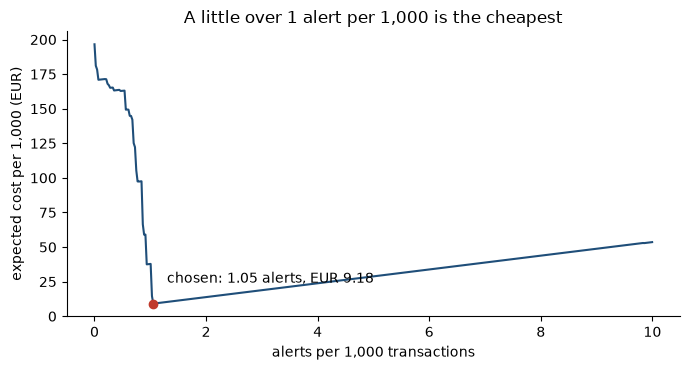

In [2]:
busy = curve[curve["alerts_per_1000"] <= 10]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(busy["alerts_per_1000"], busy["cost_per_1000"], color="#1f4e79")
pick = val["at_threshold"]
ax.plot(pick["alerts_per_1000"], pick["cost_per_1000"], "o", color="#c0392b")
ax.annotate(
    f"chosen: {pick['alerts_per_1000']:.2f} alerts, EUR {pick['cost_per_1000']:.2f}",
    (pick["alerts_per_1000"], pick["cost_per_1000"]),
    textcoords="offset points",
    xytext=(10, 15),
)
ax.set_xlabel("alerts per 1,000 transactions")
ax.set_ylabel("expected cost per 1,000 (EUR)")
ax.set_title("A little over 1 alert per 1,000 is the cheapest")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("reports/figures/cost_curve.png", dpi=150)
print("threshold", round(chosen["threshold"], 4))

In [3]:
pd.Series(val["missed_fraud_amounts"], name="missed fraud amount (EUR)").describe().round(2)

count     13.00
mean      12.87
std       29.61
min        0.00
25%        0.76
50%        1.00
75%        8.00
max      108.51
Name: missed fraud amount (EUR), dtype: float64

## Findings

1. **The model cuts expected losses by 95%:** €9.18 per 1,000 transactions against €196.57 with no model. It reviews about 1 transaction in 1,000 and catches 43 of the 56 validation frauds.
2. **0.5 is close but not the cheapest** (€10.26): it reviews more transactions to catch 3 more frauds, which here were worth less than the reviews.
3. **What's missed is mostly small.** 10 of the 13 missed frauds are under €10 (card testing, as day 3 suggested), and only one is over €25 (€108.51). At €5 a review, chasing the tiny ones would cost more than they're worth.
4. **A first version of the sweep missed the minimum.** It sampled 2,000 cut points by quantile, which put almost none in the top 0.15% of scores where the decision is. It now tries every distinct score, and a test checks it against the direct cost at random cuts.